# Baseline Replication: AMPT vs. Pan–Tompkins for Real-Time QRS Detection

**Reference Paper:**  
Neri, L.; Oberdier, M.T.; Augello, A.; et al. *"Algorithm for Mobile Platform-Based Real-Time QRS Detection."*
**Sensors** 2023, 23(3), 1625. ([`PAPER_REFERENCE.md`](PAPER_REFERENCE.md))

**Final Project Proposal:** [`laporan.md`](laporan.md)

---

## Notebook Overview
1. **Environment, Repository & Dataset Setup (Colab + Local Compatible):** Automatically installs `wfdb`, clones `acy_ampt` if missing, and downloads/extracts `ECG DBs` on Google Colab if not already present.
2. **Dataset Definitions (Table 1):** Configure the 6 benchmark ECG datasets (`A1`, `A2`, `B1`, `B2`, `C`, `D`).
3. **Replication Runner:** Execute `Pan–Tompkins` (`PICKUS`) and `AMPT` across all records (or load existing results from `result_replication/`).
4. **Table 2 Verification:** Compute `TP`, `FP`, `FN`, `Failed Detection`, `Error Rate (%)`, `Sensitivity (%)`, `PPV (%)`, `Accuracy (%)`, `F1 (%)`, and `Processing Time (ms / 10s)` and compare side-by-side against Table 2 of the reference paper.
5. **Figure 1 & Figure 2 Plots:** Reproduce Figure 1 (Processing Time & Efficiency Factor) and Figure 2 (F1 Correctness).
6. **Sample Waveform Inspection:** Overlay ground-truth QRS annotations and detected R-peaks on a sample ECG signal.

In [ ]:
# === Step 0: Install Dependencies & Setup Repository / Datasets (Colab & Local) ===
import os
import sys
import subprocess

# 1. Install wfdb and required packages if missing
try:
    import wfdb
except ImportError:
    print("Installing wfdb, pick, and PyWavelets...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wfdb", "pick", "PyWavelets"])
    import wfdb

PROJECT_ROOT = os.path.abspath(".")
ACY_DIR = os.path.join(PROJECT_ROOT, "acy_ampt")
RESULT_DIR = os.path.join(PROJECT_ROOT, "result_replication")
os.makedirs(RESULT_DIR, exist_ok=True)

# 2. Clone acy_ampt repository if not present (e.g., on Google Colab)
if not os.path.exists(ACY_DIR):
    print("Cloning acy_ampt repository...")
    subprocess.check_call(["git", "clone", "https://github.com/Accyourate-Group-S-p-A/acy_ampt.git", ACY_DIR])

# 3. Download and extract 'ECG DBs' if not present (e.g., on Google Colab)
ECG_DBS_DIR = os.path.join(ACY_DIR, "ECG DBs")
if not os.path.exists(ECG_DBS_DIR):
    zip_path = os.path.join(PROJECT_ROOT, "ECG DBs.zip")
    if not os.path.exists(zip_path):
        print("Downloading 'ECG DBs.zip' (~930 MB) from official Mega link...")
        # Install megatools on Linux/Colab to fetch the Mega.nz archive
        subprocess.run(["apt-get", "update", "-qq"], check=False)
        subprocess.run(["apt-get", "install", "-y", "-qq", "megatools", "unzip"], check=False)
        mega_url = "https://mega.nz/file/Q1lDRaBK#LgtQ3YkLoN-h7Zc6B5Bg-uFI0stfI1SNP2FIUm3VzDQ"
        subprocess.check_call(["megadl", "--path", zip_path, mega_url])
    print("Extracting 'ECG DBs.zip' into acy_ampt/...")
    subprocess.check_call(["unzip", "-q", "-o", zip_path, "-d", ACY_DIR])

print("Setup complete!")
print("  ACY_DIR:", ACY_DIR)
print("  ECG_DBS_DIR exists:", os.path.exists(ECG_DBS_DIR))
print("  RESULT_DIR:", RESULT_DIR)

Installing wfdb, pick, and PyWavelets...
Cloning acy_ampt repository...
Extracting 'ECG DBs.zip' into acy_ampt/...
Setup complete!
  ACY_DIR: /content/acy_ampt
  ECG_DBS_DIR exists: True
  RESULT_DIR: /content/result_replication


In [ ]:
import time
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import resample

# Add acy_ampt to Python path to use the exact reference implementations
if ACY_DIR not in sys.path:
    sys.path.insert(0, ACY_DIR)

from ecg_processing.signal_filtering import (
    bandpassFilt,
    derivateStep,
    movingAverageMeanPanTompkins,
)
from ecg_processing.signal_peak_detector import AMPT
from mit_processing.load_annotation import (
    loadAnnotationSampleFromPath,
    loadAnnotationSampleFromPathSinus,
    loadAnnotationSampleFromPathD,
)
from mit_processing.mit_analysis import checkNegative, checkPositive
from mit_processing.pan import panTompkins

print("All reference modules imported successfully!")

All reference modules imported successfully!


## 1. Dataset Specifications & Reference Benchmark Values (Table 1 & Table 2)

Consistent with Section 2.2 and Section 2.3 of the paper:
- **Tolerance window:** `150 ms` (ANSI/AAMI EC57).
- **Dataset `B1` (Normal Sinus Rhythm):** First 30 minutes (`230,400` samples at `128 Hz`) per record.
- **Dataset `B2` (Arrhythmias):** Excludes the 4 pacemaker records (`102.dat`, `104.dat`, `107.dat`, `217.dat`) that form Dataset `C`, leaving `44` records (`103,724` beats).
- **Dataset `D` (TeleHealth):** Excludes the `116` unreliable records where at least one algorithm had `0` true positives (`TP > 0` for both algorithms), leaving `134` records.

In [ ]:
TIME_WINDOW = 150  # ms (ANSI/AAMI EC57 standard)

DATASETS = [
    {
        "code": "A1",
        "description": "High Quality (PhysioNet 2014 SET-P)",
        "rel_path": "ECG DBs/A - Physionet Challange 2014/A1 - High Quality - SET-P",
        "fs": 250,
        "record_len_min": 10.0,
    },
    {
        "code": "A2",
        "description": "Low Quality (PhysioNet 2014 Training)",
        "rel_path": "ECG DBs/A - Physionet Challange 2014/A2 - Low Quality - Training",
        "fs": 360,
        "record_len_min": 10.0,
    },
    {
        "code": "B1",
        "description": "Normal Sinus Rhythm (MIT-BIH NSR DB)",
        "rel_path": "ECG DBs/B - MIT-BIH NSR & ARRHYTHMIA/B1 - NSR DB 1.0.0",
        "fs": 128,
        "record_len_min": 30.0,
    },
    {
        "code": "B2",
        "description": "Arrhythmias (MIT-BIH Arrhythmia DB)",
        "rel_path": "ECG DBs/B - MIT-BIH NSR & ARRHYTHMIA/B2 - ARRHYTHMIA DB 1.0.0",
        "fs": 360,
        "record_len_min": 30.0,
    },
    {
        "code": "C",
        "description": "Paced Rhythm (MIT-BIH Pacemaker Subset)",
        "rel_path": "ECG DBs/C - MIT-BIH Pacemaker Rhythm - part of ARRHYT DB",
        "fs": 360,
        "record_len_min": 30.0,
    },
    {
        "code": "D",
        "description": "TeleHealth (Harvard Dataverse Dry Electrode)",
        "rel_path": "ECG DBs/D - Harvard Telehealth DB",
        "fs": 500,
        "record_len_min": 0.5,
    },
]

# Reference values from Table 2, Figure 1, and Figure 2 of Neri et al. (2023)
# Format: (Annotated_Peaks, TP, FP, FN, Failed, Error_Rate_%, Sens_%, PPV_%, Acc_%, F1_%, Time_ms_per_10s)
PAPER_REFERENCE = {
    ("A1", "Pan-Tompkins"): (72415, 72073, 191, 348, 539, 0.74, 99.51, 99.75, 99.26, 99.63, 14.17),
    ("A1", "AMPT"):         (72415, 72267, 135, 148, 283, 0.39, 99.80, 99.82, 99.62, 99.81, 1.70),
    ("A2", "Pan-Tompkins"): (78618, 64653, 11137, 14065, 25202, 32.06, 80.75, 85.12, 74.09, 80.29, 18.14),
    ("A2", "AMPT"):         (78618, 64993, 8671, 13639, 22310, 28.38, 82.06, 86.37, 78.54, 83.46, 4.56),
    ("B1", "Pan-Tompkins"): (48494, 45231, 134, 2988, 3122, 6.44, 95.08, 99.74, 94.85, 97.02, 17.79),
    ("B1", "AMPT"):         (48494, 45301, 8, 3083, 3091, 6.37, 94.97, 99.98, 94.96, 97.07, 1.09),
    ("B2", "Pan-Tompkins"): (103724, 99783, 349, 3720, 4069, 3.92, 96.36, 99.66, 96.09, 97.91, 43.13),
    ("B2", "AMPT"):         (103724, 100135, 144, 3380, 3524, 3.40, 96.80, 99.83, 96.66, 98.25, 2.73),
    ("C",  "Pan-Tompkins"): (8923, 6684, 2132, 2238, 4370, 48.97, 74.93, 75.97, 64.26, 75.45, 50.24),
    ("C",  "AMPT"):         (8923, 8468, 276, 454, 730, 8.18, 96.90, 95.07, 92.81, 95.97, 2.37),
    ("D",  "Pan-Tompkins"): (6708, 3218, 972, 522, 1494, 40.10, 84.92, 77.56, 68.91, 78.15, 11.20),
    ("D",  "AMPT"):         (6708, 3394, 707, 334, 1041, 27.94, 90.00, 81.04, 76.29, 83.28, 2.37),
}

pd.DataFrame(DATASETS)

,code,description,rel_path,fs,record_len_min
0,A1,High Quality (PhysioNet 2014 SET-P),ECG DBs/A - Physionet Challange 2014/A1 - High...,250,10.0
1,A2,Low Quality (PhysioNet 2014 Training),ECG DBs/A - Physionet Challange 2014/A2 - Low ...,360,10.0
2,B1,Normal Sinus Rhythm (MIT-BIH NSR DB),ECG DBs/B - MIT-BIH NSR & ARRHYTHMIA/B1 - NSR ...,128,30.0
3,B2,Arrhythmias (MIT-BIH Arrhythmia DB),ECG DBs/B - MIT-BIH NSR & ARRHYTHMIA/B2 - ARRH...,360,30.0
4,C,Paced Rhythm (MIT-BIH Pacemaker Subset),ECG DBs/C - MIT-BIH Pacemaker Rhythm - part of...,360,30.0
5,D,TeleHealth (Harvard Dataverse Dry Electrode),ECG DBs/D - Harvard Telehealth DB,500,0.5


## 2. Replication Pipeline Functions

The helper module below replicates `runners/run_mit_resample.py` (for `A1`, `A2`, `B1`, `B2`, `C`) and `runners/run_mit_d_new.py` (for `D`), and supports multi-core execution across both Google Colab and local Jupyter environments.

In [ ]:
# Write worker function to an importable helper module so ProcessPoolExecutor works reliably on Colab & Python 3.12+
worker_code = '''import os
import sys
import time
import contextlib
import io
import numpy as np
import wfdb
from scipy.signal import resample

ACY_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "acy_ampt")
if ACY_DIR not in sys.path:
    sys.path.insert(0, ACY_DIR)

from ecg_processing.signal_filtering import (
    bandpassFilt,
    derivateStep,
    movingAverageMeanPanTompkins,
)
from ecg_processing.signal_peak_detector import AMPT
from mit_processing.load_annotation import (
    loadAnnotationSampleFromPath,
    loadAnnotationSampleFromPathSinus,
    loadAnnotationSampleFromPathD,
)
from mit_processing.mit_analysis import checkNegative, checkPositive
from mit_processing.pan import panTompkins

TIME_WINDOW = 150

def process_single_record(task):
    ds_code, full_path, filename, signal_sampling, pan, resample_ecg = task

    if ds_code == "D":
        record = np.genfromtxt(
            os.path.join(full_path, filename[:-12] + "_samples.dat"), delimiter=""
        )
        not_resampled_signal = [i for i in np.ravel(record)]
        if resample_ecg:
            ecg_sig = resample(
                not_resampled_signal,
                int(len(not_resampled_signal) * 200 / signal_sampling),
            )
            fs = 200
        else:
            ecg_sig = not_resampled_signal
            fs = 500
    else:
        rec_path = os.path.join(full_path, filename[:-4])
        if ds_code == "B1":
            record = wfdb.rdrecord(rec_path, sampfrom=0, sampto=230400, channels=[0])
        else:
            record = wfdb.rdrecord(rec_path, channels=[0])
        not_resampled_signal = [i for i in np.ravel(record.p_signal)]
        if resample_ecg:
            ecg_sig = resample(
                not_resampled_signal,
                int(len(not_resampled_signal) * 200 / signal_sampling),
            )
            fs = 200
        else:
            ecg_sig = not_resampled_signal
            fs = signal_sampling

    if not pan:
        new_ecg_filt = bandpassFilt(ecg_sig, 4, fs, 15, 5)
        derivate_signal = derivateStep(new_ecg_filt)
        squared_ecg = np.power(np.abs(derivate_signal), 2)
        integrated_ecg = movingAverageMeanPanTompkins(squared_ecg, fs)
        start_time = time.time()
        peaks, _ = AMPT(integrated_ecg, fs)
        elapsed = time.time() - start_time
    else:
        peaks, elapsed = panTompkins(ecg_sig, fs)

    if ds_code == "D":
        ann = loadAnnotationSampleFromPathD(full_path + "/", filename[:-12])
        ann = np.divide(ann, 1000)
        ann = np.multiply(ann, 500)
    elif ds_code == "B1":
        ann = loadAnnotationSampleFromPathSinus(
            full_path + "/", filename[:-4], counter=0, sampfrom=0, sampTo=230400
        )
    else:
        ann = loadAnnotationSampleFromPath(full_path + "/", filename[:-4])

    if resample_ecg:
        ann = [int(i * 200 / signal_sampling) for i in ann]

    with contextlib.redirect_stdout(io.StringIO()):
        fp = checkPositive(ann, peaks, fs, TIME_WINDOW)
        fn = checkNegative(ann, peaks, fs, TIME_WINDOW)

    return {
        "timing": elapsed,
        "file": filename,
        "Our Peaks": len(peaks),
        "Annotation Peaks": len(ann),
        "False Positive": len(fp),
        "False Negative": len(fn),
    }
'''

with open(os.path.join(PROJECT_ROOT, "_replication_worker.py"), "w", encoding="utf-8") as f:
    f.write(worker_code)

from _replication_worker import process_single_record


def run_or_load_dataset(ds_info, resample_ecg=False, force_rerun=False, workers=None):
    """Run replication for a dataset or load cached CSVs from result_replication/."""
    if workers is None:
        workers = max(1, os.cpu_count() or 2)
    ds_code = ds_info["code"]
    full_path = os.path.join(ACY_DIR, ds_info["rel_path"])
    fs = ds_info["fs"]
    out_dir = os.path.join(RESULT_DIR, ds_code)
    os.makedirs(out_dir, exist_ok=True)

    suffix = "_samples.dat" if ds_code == "D" else ".dat"
    files = sorted([f for f in os.listdir(full_path) if f.endswith(suffix)])

    results = {}
    for pan, algo_name, out_name in [
        (False, "AMPT", "YouCare_resampled.csv" if resample_ecg else "YouCare_not_resampled.csv"),
        (True, "Pan-Tompkins", "pan_resampled_1.csv" if resample_ecg else "pan_not_resampled_1.csv"),
    ]:
        out_csv = os.path.join(out_dir, out_name)
        if os.path.exists(out_csv) and not force_rerun:
            df = pd.read_csv(out_csv)
            if len(df) == len(files):
                print(f"[LOADED] {ds_code} - {algo_name}: {out_csv} ({len(df)} records)")
                results[algo_name] = df
                continue

        print(f"[RUNNING] {ds_code} ({len(files)} records) - {algo_name} (workers={workers})...")
        t0 = time.time()
        tasks = [(ds_code, full_path, f, fs, pan, resample_ecg) for f in files]
        with ProcessPoolExecutor(max_workers=workers) as ex:
            rows = list(ex.map(process_single_record, tasks))
        df = pd.DataFrame(rows)
        df.to_csv(out_csv, index=False, header=True)
        print(f"[SAVED] {ds_code} - {algo_name} -> {out_csv} ({time.time() - t0:.1f}s)")
        results[algo_name] = df

    return results

## 3. Run / Load All 6 Datasets (`A1` – `D`)

Set `FORCE_RERUN = False` to load the already-generated CSV files in `result_replication/` (if present), or `FORCE_RERUN = True` to re-execute the algorithms from scratch.

In [ ]:
FORCE_RERUN = False
RESAMPLE_200HZ = False

raw_results = {}
for ds_info in DATASETS:
    raw_results[ds_info["code"]] = run_or_load_dataset(
        ds_info, resample_ecg=RESAMPLE_200HZ, force_rerun=FORCE_RERUN
    )

[RUNNING] A1 (100 records) - AMPT (workers=2)...
[SAVED] A1 - AMPT -> /content/result_replication/A1/YouCare_not_resampled.csv (575.2s)
[RUNNING] A1 (100 records) - Pan-Tompkins (workers=2)...
[SAVED] A1 - Pan-Tompkins -> /content/result_replication/A1/pan_not_resampled_1.csv (518.3s)
[RUNNING] A2 (100 records) - AMPT (workers=2)...
[SAVED] A2 - AMPT -> /content/result_replication/A2/YouCare_not_resampled.csv (713.1s)
[RUNNING] A2 (100 records) - Pan-Tompkins (workers=2)...
[SAVED] A2 - Pan-Tompkins -> /content/result_replication/A2/pan_not_resampled_1.csv (656.9s)
[RUNNING] B1 (18 records) - AMPT (workers=2)...
[SAVED] B1 - AMPT -> /content/result_replication/B1/YouCare_not_resampled.csv (1041.9s)
[RUNNING] B1 (18 records) - Pan-Tompkins (workers=2)...
[SAVED] B1 - Pan-Tompkins -> /content/result_replication/B1/pan_not_resampled_1.csv (1102.8s)
[RUNNING] B2 (48 records) - AMPT (workers=2)...
[SAVED] B2 - AMPT -> /content/result_replication/B2/YouCare_not_resampled.csv (2403.0s)
[RUNNI

## 4. Evaluate Correctness & Efficiency Metrics (Table 2 Comparison)

Using Equations (8)–(12) from `PAPER_REFERENCE.md`:
- $\text{Total Error Rate} = \frac{FN + FP}{TB}$
- $\text{Sensitivity} = \frac{TP}{TP + FN}$
- $\text{Positive Predictive Value (PPV)} = \frac{TP}{TP + FP}$
- $\text{Accuracy} = \frac{TP}{TP + FP + FN}$
- $F_1 = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$

In [6]:
summary_rows = []

for ds_info in DATASETS:
    ds = ds_info["code"]
    rec_len_min = ds_info["record_len_min"]
    chunks_per_rec = (rec_len_min * 60.0) / 10.0  # Number of 10s intervals per record

    yc = raw_results[ds]["AMPT"].copy()
    pm = raw_results[ds]["Pan-Tompkins"].copy()
    yc["tp"] = yc["Our Peaks"] - yc["False Positive"]
    pm["tp"] = pm["Our Peaks"] - pm["False Positive"]

    if ds == "B2":
        # Exclude the 4 pacemaker records (Dataset C) as specified in Table 1 (44 records)
        mask = ~yc["file"].isin(["102.dat", "104.dat", "107.dat", "217.dat"])
        yc_eval, pm_eval = yc[mask].copy(), pm[mask].copy()
        ann_total = int(yc_eval["Annotation Peaks"].sum())
    elif ds == "D":
        # Exclude the 116 records where either algorithm detected 0 TP (leaving 134 valid records)
        mask = (yc["tp"] > 0) & (pm["tp"] > 0)
        yc_eval, pm_eval = yc[mask].copy(), pm[mask].copy()
        ann_total = int(yc["Annotation Peaks"].sum())
    else:
        yc_eval, pm_eval = yc.copy(), pm.copy()
        ann_total = int(yc_eval["Annotation Peaks"].sum())

    for algo, df in [("Pan-Tompkins", pm_eval), ("AMPT", yc_eval)]:
        tp = int(df["tp"].sum())
        fp = int(df["False Positive"].sum())
        fn = int(df["False Negative"].sum())
        failed = fp + fn
        ann_sub = int(df["Annotation Peaks"].sum())
        err = round(failed / ann_sub * 100, 2)

        tp_r = df["tp"]
        fp_r = df["False Positive"]
        fn_r = df["False Negative"]
        sens = round((tp_r / (tp_r + fn_r) * 100).mean(), 2)
        ppv = round((tp_r / (tp_r + fp_r) * 100).mean(), 2)
        acc = round((tp_r / (tp_r + fp_r + fn_r) * 100).mean(), 2)
        f1 = round((2 * tp_r / (2 * tp_r + fp_r + fn_r) * 100).mean(), 2)
        time_per_10s_ms = round((df["timing"].mean() * 1000.0) / chunks_per_rec, 2)

        p_ann, p_tp, p_fp, p_fn, p_fail, p_err, p_sens, p_ppv, p_acc, p_f1, p_time = PAPER_REFERENCE[(ds, algo)]

        summary_rows.append({
            "Dataset": ds,
            "Algorithm": algo,
            "Records": len(df),
            "Annotated Peaks (Ours / Paper)": f"{ann_total:,} / {p_ann:,}",
            "TP (Ours / Paper)": f"{tp:,} / {p_tp:,}",
            "FP (Ours / Paper)": f"{fp:,} / {p_fp:,}",
            "FN (Ours / Paper)": f"{fn:,} / {p_fn:,}",
            "Failed (Ours / Paper)": f"{failed:,} / {p_fail:,}",
            "Error Rate % (Ours / Paper)": f"{err:.2f} / {p_err:.2f}",
            "Sensitivity % (Ours / Paper)": f"{sens:.2f} / {p_sens:.2f}",
            "PPV % (Ours / Paper)": f"{ppv:.2f} / {p_ppv:.2f}",
            "Accuracy % (Ours / Paper)": f"{acc:.2f} / {p_acc:.2f}",
            "F1 % (Ours / Paper)": f"{f1:.2f} / {p_f1:.2f}",
            "F1_Numeric": f1,
            "Time_per_10s_ms": time_per_10s_ms,
            "Paper_Time_per_10s_ms": p_time,
        })

comparison_df = pd.DataFrame(summary_rows)
comparison_df.to_csv(os.path.join(RESULT_DIR, "table2_replication_summary.csv"), index=False)
display_cols = [
    "Dataset", "Algorithm", "Records",
    "Annotated Peaks (Ours / Paper)",
    "TP (Ours / Paper)", "FP (Ours / Paper)", "FN (Ours / Paper)", "Failed (Ours / Paper)",
    "Error Rate % (Ours / Paper)", "Sensitivity % (Ours / Paper)",
    "PPV % (Ours / Paper)", "Accuracy % (Ours / Paper)", "F1 % (Ours / Paper)",
]
comparison_df[display_cols]

,Dataset,Algorithm,Records,Annotated Peaks (Ours / Paper),TP (Ours / Paper),FP (Ours / Paper),FN (Ours / Paper),Failed (Ours / Paper),Error Rate % (Ours / Paper),Sensitivity % (Ours / Paper),PPV % (Ours / Paper),Accuracy % (Ours / Paper),F1 % (Ours / Paper)
0,A1,Pan-Tompkins,100,"72,415 / 72,415","72,073 / 72,073",191 / 191,348 / 348,539 / 539,0.74 / 0.74,99.51 / 99.51,99.75 / 99.75,99.26 / 99.26,99.63 / 99.63
1,A1,AMPT,100,"72,415 / 72,415","72,267 / 72,267",135 / 135,148 / 148,283 / 283,0.39 / 0.39,99.80 / 99.80,99.82 / 99.82,99.62 / 99.62,99.81 / 99.81
2,A2,Pan-Tompkins,100,"78,618 / 78,618","64,653 / 64,653","11,137 / 11,137","14,065 / 14,065","25,202 / 25,202",32.06 / 32.06,80.75 / 80.75,85.12 / 85.12,74.09 / 74.09,80.29 / 80.29
3,A2,AMPT,100,"78,618 / 78,618","64,993 / 64,993","8,671 / 8,671","13,639 / 13,639","22,310 / 22,310",28.38 / 28.38,82.06 / 82.06,86.37 / 86.37,78.54 / 78.54,83.46 / 83.46
4,B1,Pan-Tompkins,18,"48,494 / 48,494","45,231 / 45,231",134 / 134,"2,988 / 2,988","3,122 / 3,122",6.44 / 6.44,95.08 / 95.08,99.74 / 99.74,94.85 / 94.85,97.02 / 97.02
5,B1,AMPT,18,"48,494 / 48,494","45,301 / 45,301",8 / 8,"3,083 / 3,083","3,091 / 3,091",6.37 / 6.37,94.97 / 94.97,99.98 / 99.98,94.96 / 94.96,97.07 / 97.07
6,B2,Pan-Tompkins,44,"103,724 / 103,724","99,783 / 99,783",349 / 349,"3,720 / 3,720","4,069 / 4,069",3.92 / 3.92,96.36 / 96.36,99.66 / 99.66,96.09 / 96.09,97.91 / 97.91
7,B2,AMPT,44,"103,724 / 103,724","100,135 / 100,135",144 / 144,"3,380 / 3,380","3,524 / 3,524",3.40 / 3.40,96.80 / 96.80,99.83 / 99.83,96.66 / 96.66,98.25 / 98.25
8,C,Pan-Tompkins,4,"8,923 / 8,923","6,684 / 6,684","2,132 / 2,132","2,238 / 2,238","4,370 / 4,370",48.97 / 48.97,74.93 / 74.93,75.97 / 75.97,64.26 / 64.26,75.45 / 75.45
9,C,AMPT,4,"8,923 / 8,923","8,468 / 8,468",276 / 276,454 / 454,730 / 730,8.18 / 8.18,95.07 / 96.90,96.90 / 95.07,92.81 / 92.81,95.97 / 95.97


## 5. Reproduce Figure 1 (Processing Time & Efficiency Factor) and Figure 2 (F1 Correctness)

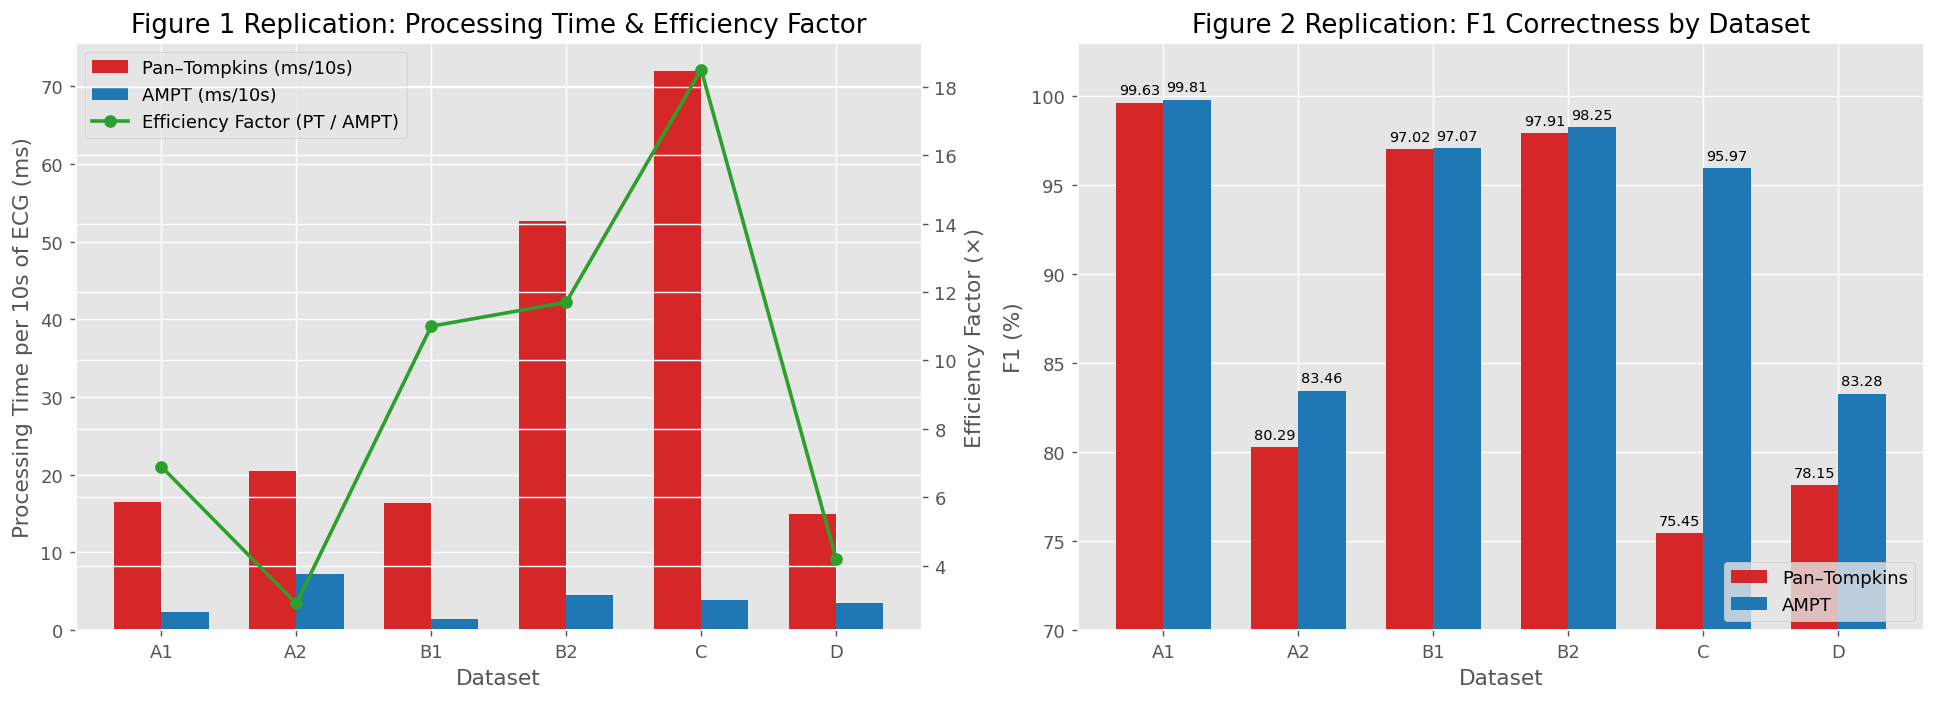

In [7]:
ds_labels = ["A1", "A2", "B1", "B2", "C", "D"]
x = np.arange(len(ds_labels))
width = 0.35

pt_f1 = [comparison_df[(comparison_df.Dataset == d) & (comparison_df.Algorithm == "Pan-Tompkins")]["F1_Numeric"].values[0] for d in ds_labels]
ampt_f1 = [comparison_df[(comparison_df.Dataset == d) & (comparison_df.Algorithm == "AMPT")]["F1_Numeric"].values[0] for d in ds_labels]

pt_t = [comparison_df[(comparison_df.Dataset == d) & (comparison_df.Algorithm == "Pan-Tompkins")]["Time_per_10s_ms"].values[0] for d in ds_labels]
ampt_t = [comparison_df[(comparison_df.Dataset == d) & (comparison_df.Algorithm == "AMPT")]["Time_per_10s_ms"].values[0] for d in ds_labels]
eff_factor = [round(p / a, 1) for p, a in zip(pt_t, ampt_t)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=130)

# --- Subplot 1: Figure 1 Replication (Processing Time & Efficiency Factor) ---
ax1 = axes[0]
b1 = ax1.bar(x - width / 2, pt_t, width, label="Pan–Tompkins (ms/10s)", color="#d62728")
b2 = ax1.bar(x + width / 2, ampt_t, width, label="AMPT (ms/10s)", color="#1f77b4")
ax1.set_ylabel("Processing Time per 10s of ECG (ms)")
ax1.set_xlabel("Dataset")
ax1.set_xticks(x)
ax1.set_xticklabels(ds_labels)
ax1.set_title("Figure 1 Replication: Processing Time & Efficiency Factor")

ax1_twin = ax1.twinx()
ax1_twin.plot(x, eff_factor, color="#2ca02c", marker="o", linewidth=2, label="Efficiency Factor (PT / AMPT)")
ax1_twin.set_ylabel("Efficiency Factor (×)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# --- Subplot 2: Figure 2 Replication (F1 Correctness) ---
ax2 = axes[1]
r1 = ax2.bar(x - width / 2, pt_f1, width, label="Pan–Tompkins", color="#d62728")
r2 = ax2.bar(x + width / 2, ampt_f1, width, label="AMPT", color="#1f77b4")
ax2.set_ylabel("F1 (%)")
ax2.set_xlabel("Dataset")
ax2.set_xticks(x)
ax2.set_xticklabels(ds_labels)
ax2.set_ylim(70, 103)
ax2.set_title("Figure 2 Replication: F1 Correctness by Dataset")
ax2.legend(loc="lower right")
ax2.bar_label(r1, fmt="%.2f", padding=3, fontsize=8)
ax2.bar_label(r2, fmt="%.2f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "replication_figures_1_and_2.png"))
plt.show()

## 6. Qualitative Inspection on a Sample Record

Visualize a 10-second segment of an ECG trace alongside ground-truth annotations and the R-peaks detected by `AMPT` and `Pan–Tompkins`.

In [ ]:
# Example: Inspect record 100 from Dataset A1 (or change to A2 / B2 to inspect noisy / arrhythmic segments)
sample_path = os.path.join(ACY_DIR, "ECG DBs/A - Physionet Challange 2014/A1 - High Quality - SET-P/100")
fs_sample = 250
record = wfdb.rdrecord(sample_path, channels=[0])
ecg_sig = np.ravel(record.p_signal)
ann_sample = loadAnnotationSampleFromPath(
    os.path.join(ACY_DIR, "ECG DBs/A - Physionet Challange 2014/A1 - High Quality - SET-P/"), "100"
)

# Run AMPT
filt = bandpassFilt(ecg_sig, 4, fs_sample, 15, 5)
deriv = derivateStep(filt)
sq = np.power(np.abs(deriv), 2)
mwi = movingAverageMeanPanTompkins(sq, fs_sample)
ampt_peaks, _ = AMPT(mwi, fs_sample)

# Run Pan-Tompkins
pt_peaks, _ = panTompkins(ecg_sig, fs_sample)

# Plot first 10 seconds
n_plot = 10 * fs_sample
t_axis = np.arange(n_plot) / fs_sample
ann_seg = [p for p in ann_sample if p < n_plot]
ampt_seg = [p for p in ampt_peaks if p < n_plot]
pt_seg = [p for p in pt_peaks if p < n_plot]

plt.figure(figsize=(14, 4), dpi=130)
plt.plot(t_axis, ecg_sig[:n_plot], color="black", alpha=0.75, linewidth=1.0, label="Raw ECG")
plt.scatter(np.array(ann_seg) / fs_sample, ecg_sig[ann_seg], color="green", marker="o", s=60, label="Ground Truth Annotation")
plt.scatter(np.array(ampt_seg) / fs_sample, ecg_sig[ampt_seg], color="#1f77b4", marker="x", s=60, label="AMPT Detected Peaks")
plt.scatter(np.array(pt_seg) / fs_sample, ecg_sig[pt_seg], color="#d62728", marker="+", s=60, label="Pan–Tompkins Detected Peaks")
plt.title("Sample ECG Waveform & QRS Detections (First 10 Seconds — Record 100, Dataset A1)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()